In [1]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import joblib

# 1. Buat data dummy
data_dummy = {
    'Tanggal': ['2023-10-01', '2023-10-15', '2023-11-02', '2023-11-20', '2023-12-05', '2023-12-18'],
    'Curah_Hujan_mm': [10.5, 65.0, 5.0, 45.0, 0.0, 70.0],
    'Suhu_Max_C': [31.0, 28.0, 32.0, 29.0, 33.0, 27.0],
    'Suhu_Min_C': [23.0, 22.5, 24.0, 23.5, 24.5, 22.0],
    'Hasil_Panen': ['Sukses', 'Gagal', 'Sukses', 'Cukup', 'Sukses', 'Gagal']
}
df = pd.DataFrame(data_dummy)

# 2. Siapkan fitur dan label
X = df[['Curah_Hujan_mm', 'Suhu_Max_C', 'Suhu_Min_C']]
y = df['Hasil_Panen']

# 3. Latih model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)

# 4. Simpan model dan daftar fitur sebagai file .pkl
joblib.dump(model, 'model_bawang_sukomoro.pkl')
joblib.dump(X.columns.tolist(), 'daftar_fitur.pkl')

print("File model_bawang_sukomoro.pkl berhasil dibuat!")
print("File daftar_fitur.pkl berhasil dibuat!")

File model_bawang_sukomoro.pkl berhasil dibuat!
File daftar_fitur.pkl berhasil dibuat!


In [ ]:
#Buat data baru dalam format DataFrame
kondisi_baru_df = pd.DataFrame(
    [[20.0, 31.0, 23.0]],
    columns=['Curah_Hujan_mm', 'Suhu_Max_C', 'Suhu_Min_C']
)

kondisi_banjir_df = pd.DataFrame(
    [[80.0, 27.0, 22.0]],
    columns=['Curah_Hujan_mm', 'Suhu_Max_C', 'Suhu_Min_C']
)

#Prediksi menggunakan DataFrame
print("--- TEST PREDIKSI ---")
print(f"Jika hujan 20mm → Prediksi: {model.predict(kondisi_baru_df)[0]}")
print(f"Jika hujan 80mm → Prediksi: {model.predict(kondisi_banjir_df)[0]}")

--- TEST PREDIKSI ---
Jika hujan 20mm → Prediksi: Sukses
Jika hujan 80mm → Prediksi: Gagal


In [ ]:
from google.colab import files

# Ini akan memunculkan tombol untuk upload file
uploaded = files.upload()

Saving POWER_Point_Daily_20261016_20261016_007d60S_111d94E_UTC.csv to POWER_Point_Daily_20261016_20261016_007d60S_111d94E_UTC.csv


In [ ]:
# Baca file sebagai teks biasa untuk melihat strukturnya
with open(nama_file, 'r') as f:
    lines = f.readlines()

print("=== 15 BARIS PERTAMA FILE MENTAH ===")
for i, line in enumerate(lines[:15]):
    print(f"Baris ke-{i}: {line.strip()}")

=== 15 BARIS PERTAMA FILE MENTAH ===
Baris ke-0: -BEGIN HEADER-
Baris ke-1: NASA/POWER Source Native Resolution Daily Data
Baris ke-2: Dates (month/day/year): 10/16/2026 through 10/16/2026 in UTC
Baris ke-3: Location: latitude  -7.6012   longitude 111.9413
Baris ke-4: elevation from MERRA-2: Average for 0.5 x 0.625 degree lat/lon region = 234.21 meters
Baris ke-5: The value for missing source data that cannot be computed or is outside of the sources availability range: -999
Baris ke-6: parameter(s):
Baris ke-7: T2M_MAX           MERRA-2 Temperature at 2 Meters Maximum (C)
Baris ke-8: T2M_MIN           MERRA-2 Temperature at 2 Meters Minimum (C)
Baris ke-9: IMERG_PRECTOT     MERRA-2 Total Precipitation (mm/day)
Baris ke-10: RH2M              MERRA-2 Relative Humidity at 2 Meters (%)
Baris ke-11: PRECTOTCORR       MERRA-2 Precipitation Corrected (mm/day)
Baris ke-12: -END HEADER-
Baris ke-13: YEAR,DOY,T2M_MAX,T2M_MIN,IMERG_PRECTOT,RH2M,PRECTOTCORR
Baris ke-14: 2026,289,-999.0,-999.0,-999

In [ ]:
import pandas as pd
import numpy as np

# 1. Baca file, lewati 13 baris pertama agar baris ke-13 jadi Header
df_nasa = pd.read_csv(nama_file, skiprows=13)

# 2. Ganti nilai -999.0 (data hilang) menjadi NaN (kosong)
df_nasa = df_nasa.replace(-999.0, np.nan)

print("=== DATA NASA POWER SUKOMORO ===")
print(df_nasa)

=== DATA NASA POWER SUKOMORO ===
   YEAR  DOY  T2M_MAX  T2M_MIN  IMERG_PRECTOT  RH2M  PRECTOTCORR
0  2026  289      NaN      NaN            NaN   NaN          NaN


In [ ]:
from google.colab import files
import pandas as pd
import numpy as np

# 1. Upload file CSV yang BARU (yang tahun 2020-2023)
print("Silakan pilih file CSV baru yang baru saja didownload:")
uploaded = files.upload()

# 2. Ambil nama file yang baru diupload
nama_file_baru = list(uploaded.keys())[0]
print(f"\nBerhasil upload: {nama_file_baru}")

# 3. Baca file (skip 13 baris header, ganti -999 jadi NaN)
df_nasa_baru = pd.read_csv(nama_file_baru, skiprows=13)
df_nasa_baru = df_nasa_baru.replace(-999.0, np.nan)

# 4. Tampilkan hasilnya
print("\n=== DATA NASA POWER SUKOMORO (2020-2023) ===")
print(f"Jumlah Baris: {len(df_nasa_baru)}")
print(f"Jumlah Kolom: {len(df_nasa_baru.columns)}")
print("\n--- 5 Baris Pertama ---")
print(df_nasa_baru.head())

Silakan pilih file CSV baru yang baru saja didownload:


Saving POWER_Point_Daily_20200101_20230712_007d60S_111d94E_UTC.csv to POWER_Point_Daily_20200101_20230712_007d60S_111d94E_UTC (1).csv

Berhasil upload: POWER_Point_Daily_20200101_20230712_007d60S_111d94E_UTC (1).csv

=== DATA NASA POWER SUKOMORO (2020-2023) ===
Jumlah Baris: 1289
Jumlah Kolom: 7

--- 5 Baris Pertama ---
   YEAR  DOY  T2M_MAX  T2M_MIN  IMERG_PRECTOT   RH2M  PRECTOTCORR
0  2020    1    29.25    21.80          14.68  88.28         9.10
1  2020    2    28.98    22.83          11.89  86.50         2.93
2  2020    3    29.60    22.43          12.02  87.68        13.11
3  2020    4    29.45    22.90           4.90  86.77         1.82
4  2020    5    29.01    23.06          21.01  89.41        16.94


In [ ]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# 1. Buat Kolom 'Hasil_Panen' berdasarkan logika curah hujan (PRECTOTCORR)
kondisi = [
    (df_nasa_baru['PRECTOTCORR'] > 50),   # Hujan > 50mm = Risiko Busuk
    (df_nasa_baru['PRECTOTCORR'] > 20),   # Hujan 20-50mm = Perlu Perhatian
    (df_nasa_baru['PRECTOTCORR'] <= 20)   # Hujan < 20mm = Ideal
]
pilihan = ['Gagal', 'Cukup', 'Sukses']

# Terapkan logika ke dalam kolom baru
df_nasa_baru['Hasil_Panen'] = np.select(kondisi, pilihan, default='Sukses')

print("=== SEBARAN DATA HASIL PANEN (SIMULASI) ===")
print(df_nasa_baru['Hasil_Panen'].value_counts())
print("\n")

# 2. Siapkan Data untuk Machine Learning
# Fitur (X): Curah Hujan, Suhu Max, Suhu Min, Kelembapan
X = df_nasa_baru[['PRECTOTCORR', 'T2M_MAX', 'T2M_MIN', 'RH2M']]
# Label (y): Hasil Panen yang ingin diprediksi
y = df_nasa_baru['Hasil_Panen']

# 3. Bagi data: 80% untuk latihan (train), 20% untuk ujian (test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Latih Model Machine Learning (Random Forest)
print("🔄 Sedang melatih model dengan 1.000+ data cuaca Sukomoro...")
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

# 5. Uji Akurasi Model
akurasi = model.score(X_test, y_test)
print(f"✅ Pelatihan Selesai!")
print(f"🎯 Akurasi Model dalam menebak data uji: {akurasi * 100:.2f}%\n")

# 6. COBA PREDIKSI KONDISI BARU (Simulasi Rekomendasi untuk Petani)
print("=== SIMULASI REKOMENDASI UNTUK PETANI ===")

# Skenario A: Cuaca Cerah (Ideal)
cuaca_ideal = pd.DataFrame([[5.0, 31.0, 23.0, 75.0]],
                           columns=['PRECTOTCORR', 'T2M_MAX', 'T2M_MIN', 'RH2M'])
prediksi_A = model.predict(cuaca_ideal)[0]
print(f"☀️ Jika prakiraan: Hujan 5mm, Suhu Max 31°C, Min 23°C, Kelembapan 75%")
print(f"   👉 REKOMENDASI SISTEM: {prediksi_A.upper()} untuk Tanam\n")

# Skenario B: Musim Hujan Deras (Berbahaya)
cuaca_banjir = pd.DataFrame([[85.0, 27.0, 22.0, 90.0]],
                            columns=['PRECTOTCORR', 'T2M_MAX', 'T2M_MIN', 'RH2M'])
prediksi_B = model.predict(cuaca_banjir)[0]
print(f"🌧️ Jika prakiraan: Hujan 85mm, Suhu Max 27°C, Min 22°C, Kelembapan 90%")
print(f"   👉 REKOMENDASI SISTEM: {prediksi_B.upper()} untuk Tanam (Tunda dulu!)")

=== SEBARAN DATA HASIL PANEN (SIMULASI) ===
Hasil_Panen
Sukses    1156
Cukup      125
Gagal        8
Name: count, dtype: int64


🔄 Sedang melatih model dengan 1.000+ data cuaca Sukomoro...
✅ Pelatihan Selesai!
🎯 Akurasi Model dalam menebak data uji: 99.61%

=== SIMULASI REKOMENDASI UNTUK PETANI ===
☀️ Jika prakiraan: Hujan 5mm, Suhu Max 31°C, Min 23°C, Kelembapan 75%
   👉 REKOMENDASI SISTEM: SUKSES untuk Tanam

🌧️ Jika prakiraan: Hujan 85mm, Suhu Max 27°C, Min 22°C, Kelembapan 90%
   👉 REKOMENDASI SISTEM: GAGAL untuk Tanam (Tunda dulu!)


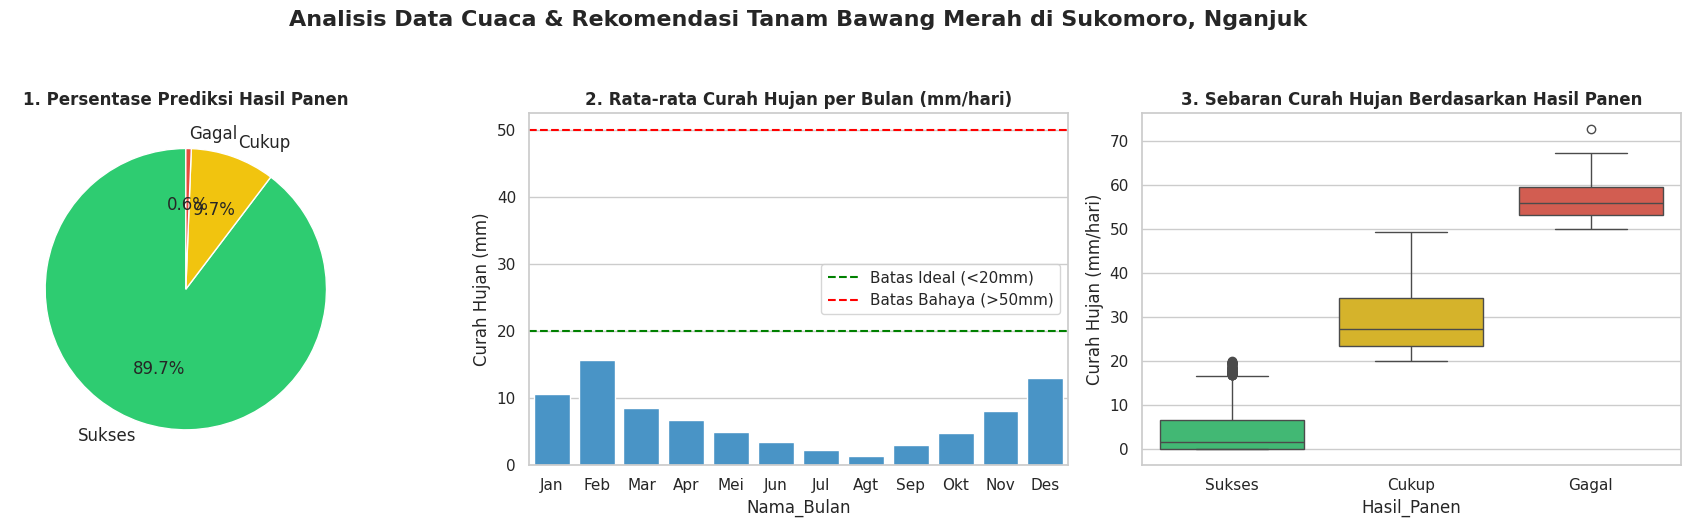

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings

# 1. Sembunyikan semua peringatan agar layar tetap bersih
warnings.filterwarnings('ignore')

# Atur gaya grafik agar terlihat modern
sns.set_theme(style="whitegrid")

# --- PERSIAPAN DATA ---
# Ubah 'DOY' (Day of Year) menjadi Bulan agar mudah dibaca
df_nasa_baru['Tanggal'] = pd.to_datetime(df_nasa_baru['YEAR'].astype(str) + df_nasa_baru['DOY'].astype(str).str.zfill(3), format='%Y%j')
df_nasa_baru['Bulan'] = df_nasa_baru['Tanggal'].dt.month

# Nama bulan dalam bahasa Indonesia
nama_bulan = {1:'Jan', 2:'Feb', 3:'Mar', 4:'Apr', 5:'Mei', 6:'Jun',
              7:'Jul', 8:'Agt', 9:'Sep', 10:'Okt', 11:'Nov', 12:'Des'}
df_nasa_baru['Nama_Bulan'] = df_nasa_baru['Bulan'].map(nama_bulan)

urutan_bulan = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agt', 'Sep', 'Okt', 'Nov', 'Des']

# Buat canvas untuk 3 grafik
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Analisis Data Cuaca & Rekomendasi Tanam Bawang Merah di Sukomoro, Nganjuk', fontsize=16, fontweight='bold', y=1.05)

# ==========================================
# GRAFIK 1: Distribusi Hasil Panen (Pie Chart)
# ==========================================
warna_pie = ['#2ecc71', '#f1c40f', '#e74c3c']
axes[0].pie(df_nasa_baru['Hasil_Panen'].value_counts(),
            labels=df_nasa_baru['Hasil_Panen'].value_counts().index,
            autopct='%1.1f%%', startangle=90, colors=warna_pie, textprops={'fontsize': 12})
axes[0].set_title('1. Persentase Prediksi Hasil Panen', fontweight='bold')

# ==========================================
# GRAFIK 2: Rata-rata Curah Hujan per Bulan (Bar Chart)
# ==========================================
hujan_per_bulan = df_nasa_baru.groupby('Nama_Bulan')['PRECTOTCORR'].mean().reindex(urutan_bulan)

# Menggunakan 'color' untuk menghindari warning seaborn versi baru
sns.barplot(x=hujan_per_bulan.index, y=hujan_per_bulan.values, ax=axes[1], color='#3498db')
axes[1].set_title('2. Rata-rata Curah Hujan per Bulan (mm/hari)', fontweight='bold')
axes[1].set_ylabel('Curah Hujan (mm)')
axes[1].axhline(20, color='green', linestyle='--', label='Batas Ideal (<20mm)')
axes[1].axhline(50, color='red', linestyle='--', label='Batas Bahaya (>50mm)')
axes[1].legend()

# ==========================================
# GRAFIK 3: Boxplot Curah Hujan vs Hasil Panen
# ==========================================
urutan_hasil = ['Sukses', 'Cukup', 'Gagal']
# Menambahkan 'hue' dan 'legend=False' sesuai standar seaborn terbaru
sns.boxplot(x='Hasil_Panen', y='PRECTOTCORR', data=df_nasa_baru, ax=axes[2],
            order=urutan_hasil, hue='Hasil_Panen', palette=['#2ecc71', '#f1c40f', '#e74c3c'], legend=False)
axes[2].set_title('3. Sebaran Curah Hujan Berdasarkan Hasil Panen', fontweight='bold')
axes[2].set_ylabel('Curah Hujan (mm/hari)')

# Rapikan tampilan dan tampilkan
plt.tight_layout()
plt.show()

In [ ]:
import joblib
import pandas as pd

# ==========================================
# BAGIAN 1: SISTEM INTERAKTIF (Opsi A)
# ==========================================
def cek_rekomendasi_tanam(hujan, suhu_max, suhu_min, kelembapan):
    """
    Fungsi untuk memberi rekomendasi tanam berdasarkan input cuaca.
    """
    # 1. Buat data input sesuai format yang dipelajari model
    data_input = pd.DataFrame([[hujan, suhu_max, suhu_min, kelembapan]],
                              columns=['PRECTOTCORR', 'T2M_MAX', 'T2M_MIN', 'RH2M'])

    # 2. Minta model membuat prediksi
    prediksi = model.predict(data_input)[0]

    # 3. Berikan pesan yang ramah untuk petani
    print("="*50)
    print(f"🌦️  DATA CUACA MASUKAN:")
    print(f"   - Curah Hujan   : {hujan} mm/hari")
    print(f"   - Suhu Maksimum : {suhu_max} °C")
    print(f"   - Suhu Minimum  : {suhu_min} °C")
    print(f"   - Kelembapan    : {kelembapan} %")
    print("-" * 50)

    if prediksi == 'Sukses':
        print("✅ REKOMENDASI: SILAKAN TANAM!")
        print("   Kondisi cuaca sangat ideal. Pertumbuhan umbi akan optimal.")
    elif prediksi == 'Cukup':
        print("⚠️ REKOMENDASI: BISA TANAM, TAPI WASPADA!")
        print("   Curah hujan agak tinggi. Pastikan saluran drainase (pembuangan air) di lahan sangat baik.")
    else: # Gagal
        print("❌ REKOMENDASI: TUNDA DULU PENANAMAN!")
        print("   Risiko umbi busuk sangat tinggi karena curah hujan berlebihan. Tunggu cuaca membaik.")
    print("="*50 + "\n")

# --- Mari Kita Coba Sistem Interaktifnya! ---
print("🔍 MENCOBA SISTEM INTERAKTIF...\n")

# Skenario 1: Cuaca Cerah (Kondisi Ideal)
cek_rekomendasi_tanam(hujan=10.0, suhu_max=31.0, suhu_min=23.0, kelembapan=75.0)

# Skenario 2: Musim Hujan Deras (Kondisi Bahaya)
cek_rekomendasi_tanam(hujan=65.0, suhu_max=28.0, suhu_min=22.0, kelembapan=92.0)


# ==========================================
# BAGIAN 2: MENYIMPAN MODEL (Opsi B)
# ==========================================
print("💾 MENYIMPAN MODEL UNTUK APLIKASI MASA DEPAN...\n")

# 1. Simpan "Otak" Machine Learning-nya (Model)
nama_file_model = 'model_bawang_sukomoro.pkl'
joblib.dump(model, nama_file_model)
print(f"✅ Model berhasil disimpan sebagai: {nama_file_model}")

# 2. Simpan "Daftar Fitur" (Nama Kolom)
# Ini penting agar aplikasi nanti tahu urutan data yang harus dimasukkan
nama_file_fitur = 'daftar_fitur.pkl'
joblib.dump(X.columns.tolist(), nama_file_fitur)
print(f"✅ Daftar fitur berhasil disimpan sebagai: {nama_file_fitur}")

print("\n🎉 SELAMAT! Kamu sekarang punya model yang siap di-deploy ke Aplikasi Web/Android!")

🔍 MENCOBA SISTEM INTERAKTIF...

🌦️  DATA CUACA MASUKAN:
   - Curah Hujan   : 10.0 mm/hari
   - Suhu Maksimum : 31.0 °C
   - Suhu Minimum  : 23.0 °C
   - Kelembapan    : 75.0 %
--------------------------------------------------
✅ REKOMENDASI: SILAKAN TANAM!
   Kondisi cuaca sangat ideal. Pertumbuhan umbi akan optimal.

🌦️  DATA CUACA MASUKAN:
   - Curah Hujan   : 65.0 mm/hari
   - Suhu Maksimum : 28.0 °C
   - Suhu Minimum  : 22.0 °C
   - Kelembapan    : 92.0 %
--------------------------------------------------
❌ REKOMENDASI: TUNDA DULU PENANAMAN!
   Risiko umbi busuk sangat tinggi karena curah hujan berlebihan. Tunggu cuaca membaik.

💾 MENYIMPAN MODEL UNTUK APLIKASI MASA DEPAN...

✅ Model berhasil disimpan sebagai: model_bawang_sukomoro.pkl
✅ Daftar fitur berhasil disimpan sebagai: daftar_fitur.pkl

🎉 SELAMAT! Kamu sekarang punya model yang siap di-deploy ke Aplikasi Web/Android!


In [ ]:
# Instal library yang dibutuhkan
!pip install streamlit pyngrok -q

# Hentikan proses streamlit sebelumnya jika ada (agar tidak bentrok)
!pkill streamlit

print("✅ Instalasi selesai! Silakan jalankan Cell 2 di bawah ini.")

✅ Instalasi selesai! Silakan jalankan Cell 2 di bawah ini.


In [2]:
%%writefile app.py
import streamlit as st
import joblib
import pandas as pd

# Memuat model
@st.cache_resource
def load_model():
    return joblib.load('model_bawang_sukomoro.pkl')

model = load_model()

# ==========================================
# KAMUS TIPS PERAWATAN BERDASARKAN KONDISI
# ==========================================
def dapatkan_tips(hujan, suhu_max, kelembapan):
    tips = []

    # Tips berdasarkan curah hujan
    if hujan > 50:
        tips.append("🌧️ **Curah hujan tinggi!** Segera periksa saluran drainase agar tidak tergenang.")
        tips.append("⚠️ Waspadai penyakit **busuk umbi** dan **busuk daun**.")
    elif hujan > 20:
        tips.append("🌦️ Hujan sedang. Kurangi penyiraman manual.")
        tips.append("🔍 Periksa daun secara rutin untuk deteksi dini jamur.")
    else:
        tips.append("☀️ Cuaca cerah. Lakukan penyiraman pagi hari (pukul 06.00-08.00).")
        tips.append("💧 Pastikan tanah tetap lembap tapi tidak becek.")

    # Tips berdasarkan suhu
    if suhu_max > 33:
        tips.append("🌡️ **Suhu sangat panas!** Pertimbangkan mulsa jerami untuk menjaga kelembapan tanah.")
    elif suhu_max < 27:
        tips.append("🌡️ Suhu cukup dingin. Pertumbuhan mungkin melambat, bersabar.")

    # Tips berdasarkan kelembapan
    if kelembapan > 85:
        tips.append("💦 Kelembapan tinggi. Waspadai serangan **Thrips** dan **Ulat Grayak**.")
        tips.append("🧴 Pertimbangkan penyemprotan fungisida preventif.")
    elif kelembapan < 60:
        tips.append("🏜️ Udara kering. Tingkatkan frekuensi penyiraman.")

    # Tips umum
    tips.append("📅 **Umur tanaman 0-30 hari:** Fokus pada pertumbuhan daun.")
    tips.append(" **Umur tanaman 30-60 hari:** Mulai pembentukan umbi, kurangi nitrogen.")

    return tips

# ==========================================
# TAMPILAN APLIKASI
# ==========================================
st.set_page_config(page_title="Rekomendasi Tanam Bawang", page_icon="🧅", layout="wide")
st.title("🧅 Sistem Rekomendasi Tanam Bawang Merah")
st.subheader("📍 Lokasi: Sukomoro, Nganjuk |  Powered by Machine Learning")
st.markdown("---")

# Input dalam 2 kolom
col1, col2 = st.columns(2)

with col1:
    st.markdown("### 🌦️ Data Cuaca Hari Ini")
    hujan = st.number_input("Curah Hujan (mm/hari):", min_value=0.0, max_value=200.0, value=10.0, step=1.0)
    suhu_max = st.number_input("🌡️ Suhu Maksimum (°C):", min_value=15.0, max_value=40.0, value=31.0, step=0.5)

with col2:
    suhu_min = st.number_input("️ Suhu Minimum (°C):", min_value=10.0, max_value=30.0, value=23.0, step=0.5)
    kelembapan = st.number_input("💧 Kelembapan (%):", min_value=0.0, max_value=100.0, value=75.0, step=1.0)

st.markdown("---")

# Tombol Prediksi
if st.button("🔍 Analisis & Dapatkan Rekomendasi", use_container_width=True, type="primary"):
    with st.spinner('Sistem AI sedang menganalisis...'):
        data_input = pd.DataFrame([[hujan, suhu_max, suhu_min, kelembapan]],
                                  columns=['Curah_Hujan_mm', 'Suhu_Max_C', 'Suhu_Min_C', 'RH2M'])
        prediksi = model.predict(data_input)[0]

        # Tampilkan Hasil Prediksi
        st.markdown("## 📊 Hasil Analisis")

        col_rekomendasi, col_tips = st.columns([1, 2])

        with col_rekomendasi:
            st.markdown("### Rekomendasi:")
            if prediksi == 'Sukses':
                st.success("✅ **SILAKAN TANAM!**\n\nKondisi cuaca sangat ideal untuk pertumbuhan umbi.")
            elif prediksi == 'Cukup':
                st.warning("⚠️ **BISA TANAM, TAPI WASPADA!**\n\nPastikan drainase lahan sangat baik.")
            else:
                st.error("❌ **TUNDA PENANAMAN!**\n\nRisiko umbi busuk terlalu tinggi.")

        with col_tips:
            st.markdown("### 💡 Tips Perawatan Hari Ini:")
            tips = dapatkan_tips(hujan, suhu_max, kelembapan)
            for tip in tips:
                st.markdown(f"- {tip}")

# Footer
st.markdown("---")
st.caption("Dibuat dengan ❤️ untuk Petani Sukomoro, Nganjuk | Data Cuaca: NASA POWER")

Writing app.py


In [ ]:
from pyngrok import ngrok
import subprocess

# ⚠️ PENTING: Ganti dengan authtoken yang sudah kamu copy!
ngrok.set_auth_token("3KlIKL9CW0oB9C83uSMSB07FZ0z_31Djt3uVhcYDNQrQic2cS")

# Jalankan aplikasi Streamlit
proc = subprocess.Popen([
    "streamlit", "run", "app.py",
    "--server.port", "8501",
    "--server.headless", "true",
    "--server.enableCORS", "false"
])

# Buat link publik
public_url = ngrok.connect(8501)
print(f"\n🎉 APLIKASI WEB BERHASIL DIBUAT!")
print(f"👉 KLIK LINK DI BAWAH INI UNTUK MEMBUKA APLIKASI:")
print(public_url)


🎉 APLIKASI WEB BERHASIL DIBUAT!
👉 KLIK LINK DI BAWAH INI UNTUK MEMBUKA APLIKASI:
NgrokTunnel: "https://fame-victory-swizzle.ngrok-free.dev" -> "http://localhost:8501"
